# Dashboard de Backtest

In [15]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import glob
import os
from matplotlib.ticker import MultipleLocator
    
# --- CONFIGURATION DES CHEMINS ---
DIRS = [
    '/app/working/workspaces/FinCodeur95/duckdb/Features_Pente/',
    '/app/working/workspaces/FinCodeur95/duckdb/Features_Pente/historique résultats'
],
DIRS = [d for d in DIRS[0] if os.path.isdir(d)]
   

### --- COULEURS DOUCES ET DISTINGUABLES ---

In [11]:
C_GAIN = '#3498db'      # Bleu
C_LOSS = '#e74c3c'      # Rouge
C_CASH = '#a2d149'      # Vert amande (Almond Green)
C_CAPITAL = '#f1c40f'   # Jaune moyen

### 1. CHARGEMENT DES DONNÉES

In [20]:
summary_files = []
for d in DIRS:
    print(f'Verification du répertoire : {d}')
    summary_files.extend(glob.glob(os.path.join(d, 'knn_backtest.summary.csv')))

if not summary_files:
    raise FileNotFoundError('Aucun fichier de résumé trouvé.')

summary_df = pd.read_csv(summary_files[0])
capital_initial = summary_df['capital_initial'].iloc[0]

equity_files = []
for d in DIRS:
    equity_files.extend(glob.glob(os.path.join(d, 'knn_backtest.equity.csv')))

if not equity_files:
    raise FileNotFoundError('Aucun fichier d\'equity trouvé.')

df = pd.read_csv(equity_files[0])
df['date'] = pd.to_datetime(df['date'])
df['perf_pct'] = (df['total_equity'] / capital_initial - 1) * 100

start_date = df['date'].min().strftime('%d/%m/%Y')
end_date = df.iloc[-1]['date'].strftime('%d/%m/%Y')
print(f'Données chargées de {start_date} à {end_date}')

Verification du répertoire : /app/working/workspaces/FinCodeur95/duckdb/Features_Pente/
Données chargées de 25/03/2025 à 27/05/2026


### 2. GRAPHIQUE PRINCIPAL : Courbe Pertes et Gains

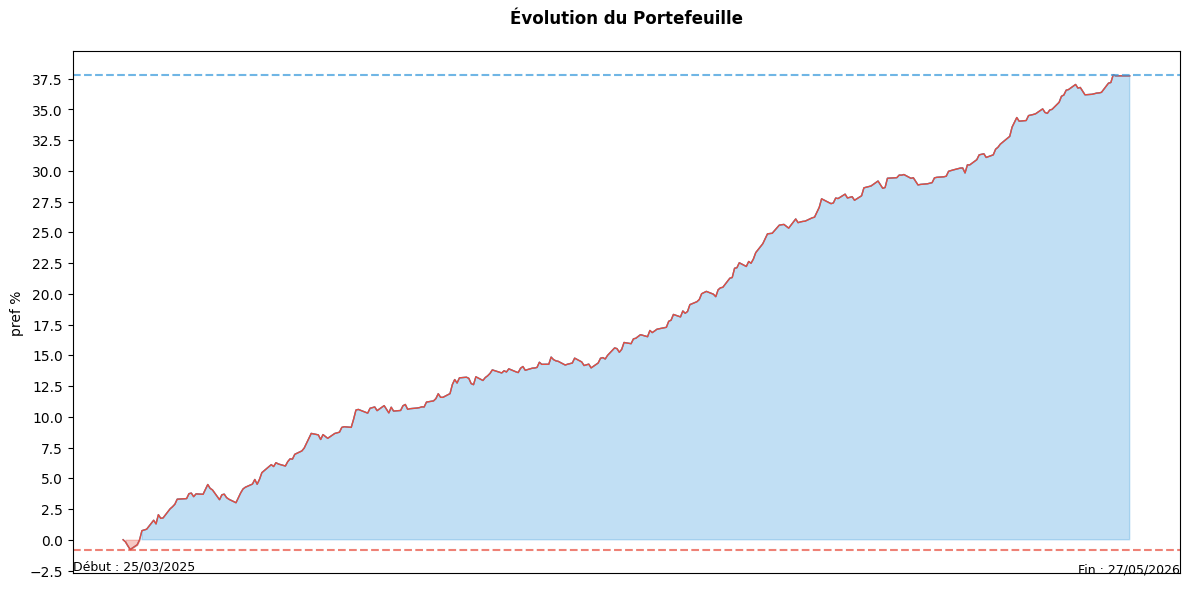

In [28]:
fig1, ax1 = plt.subplots(figsize=(12, 6))
ax1.plot(df['date'], df['perf_pct'], color=C_GAIN, linewidth=1)
ax1.plot(df['date'], df['perf_pct'], color=C_LOSS, linewidth=1)
ax1.fill_between(df['date'], 0, df['perf_pct'], where=(df['perf_pct'] >= 0), color=C_GAIN, alpha=0.3)
ax1.fill_between(df['date'], 0, df['perf_pct'], where=(df['perf_pct'] < 0), color=C_LOSS, alpha=0.3)

# Lignes pointillées max/min
max_g = df['perf_pct'].max()
min_l = df['perf_pct'].min()
ax1.axhline(y=max_g, color=C_GAIN, linestyle='--', alpha=0.7)
ax1.axhline(y=min_l, color=C_LOSS, linestyle='--', alpha=0.7)

ax1.set_ylabel('pref %')
ax1.yaxis.set_major_locator(MultipleLocator(2.5)) 
ax1.set_xticks([]) # Pas de chiffres sur l'axe X

# Bornes date (Positionnées par rapport aux axes)
ax1.text(0, 0, f'Début : {start_date}', transform=ax1.transAxes, verticalalignment='bottom', fontsize=9)
ax1.text(1, 0, f'Fin : {end_date}', transform=ax1.transAxes, horizontalalignment='right', fontsize=9)

plt.title('Évolution du Portefeuille', pad=20, fontweight='bold')
plt.tight_layout()
plt.show()

### 3. GRAPHIQUE SECONDAIRE 1 : Cash et Capital

In [ ]:
fig2, ax2 = plt.subplots(figsize=(12, 4))
# On trace le capital d'abord pour que le cash soit par dessus (rempli
ax2.plot(df['date'], df['total_equity'], color=C_CAPITAL, label='Capital')
ax2.fill_between(df['date'], 0, df['total_equity'], color=C_CAPITAL, a

ax2.plot(df['date'], df['cash'], color=C_CASH, label='Cash')
ax2.fill_between(df['date'], 0, df['cash'], color=C_CASH, alpha=0.3)

# Axes config
min_val = min(df['total_equity'].min(), df['cash'].min())
base_val = (int(min_val // 100)) * 100
ax2.set_ylim(bottom=base_val)
ax2.set_ylabel('Montant')
ax2.set_xticks([]) 

# Bornes date (même que principal)
ax2.text(0, 0, f'Début : {start_date}', transform=ax2.transAxes, verticalalignment='bottom', fontsize=9)
ax2.text(1, 0, f'Fin : {end_date}', transform=ax2.transAxes, horizonta9)

plt.title(Évolution du Cash et du Capital, pad=15)
plt.tight_layout()
plt.show()

### 4. GRAPHIQUE SECONDAIRE 2 : Histogramme Cumulé

In [ ]:
fig3, ax3 = plt.subplots(figsize=(6, 5))
cash_start = df['cash'].iloc[0]
cash_final = df['cash'].iloc[-1]
cap_final = df['total_equity'].iloc[-1]

# Calcul des parts
part1 = cash_start
part2 = cash_final - cash_start
part3 = cap_final - cash_final

widths = [part1, part2, part3]
colors = ['black', C_CASH, C_CAPITAL]
labels = [f'Cash de base ({part1:.0f})', f'Delta Cash Final ({part2:.0f})', f'Delta Capital Final ({part3:.0f})']

bottom = 0
for w, c, l in zip(widths, colors, labels):
    ax3.bar('Portefeuille', w, bottom=bottom, color=c, label=l)
    bottom += w

# Lignes de séparation (horizontales sur l'histogramme vertical)
ax3.axhline(y=cash_start, color='white', linestyle='-', linewidth=1)
ax3.axhline(y=cash_final, color='white', linestyle='-', linewidth=1)

ax3.legend(loc='upper left', fontsize=8)
plt.title(Répartition du Capital, pad=20, fontweight='bold')
plt.tight_layout()
plt.show()